# Inspect the new RGB Mandelbrot dataset

**`data/zoom4x-multiscale-128`: 900 training + 100 validation examples, 128×128 RGB.**
Each example stores aligned image evidence, a coverage mask, and the true rendered target.
The same targets support random-view generation and conditional 4× zoom refinement.

Run all cells and use the controls below. Interior, edge, corner, and unconditional examples share one format.
White mask regions contain coarse observations; they are not exact pixels to preserve. Gray missing RGB
is a placeholder and carries no evidence. This notebook does not train models or modify datasets.

Seven balanced zoom depths cover 1×, 4×, 16×, 64×, 256×, 1,024×, and 4,096× magnification. Input-to-target refinement remains 4× at every depth.

In [1]:
from functools import lru_cache
import hashlib
import html
import json
from pathlib import Path
import random

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset.py").exists())
DATA = ROOT / "data"
torch.set_num_threads(4)
plt.rcParams.update({"figure.dpi": 110, "image.interpolation": "nearest"})
rng = random.Random(20261016)
print(f"Reading {DATA}")

Reading /home/blacknoir/Projects/mandelbrot-diffusion/data


## Inventory

Sizes and image counts come from the tensors themselves. Inputs and targets on disk use [0,1].
A `records` entry contains per-image camera metadata; a manifest describes how a dataset was generated.

In [2]:
datasets = sorted(p for p in DATA.iterdir() if p.is_dir() and (p / "train.pt").exists())
assert datasets, f"No datasets found under {DATA}"

@lru_cache(maxsize=2)
def load(path):
    return torch.load(path, map_location="cpu", weights_only=True, mmap=True)

def manifest(directory):
    path = directory / "manifest.json"
    return json.loads(path.read_text()) if path.exists() else {}

def image_keys(payload):
    return ("inputs", "targets") if "inputs" in payload and "targets" in payload else ("images",)

def table(headers, rows):
    th = "".join(f"<th>{html.escape(str(v))}</th>" for v in headers)
    tr = "".join("<tr>" + "".join(f"<td>{html.escape(str(v))}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{th}</tr></thead><tbody>{tr}</tbody></table>"))

rows = []
for directory in datasets:
    train = load(directory / "train.pt")
    keys = image_keys(train)
    images = train[keys[-1]]
    val_path = directory / "val.pt"
    val_count = len(load(val_path)[keys[-1]]) if val_path.exists() else 0
    rows.append((directory.name, len(images), val_count, " × ".join(map(str, images.shape[1:])),
                 "paired zoom" if len(keys) == 2 else "images", "yes" if "masks" in train else "no"))
table(("Dataset", "Train", "Validation", "C × H × W", "Contents", "Stored masks"), rows)

Dataset,Train,Validation,C × H × W,Contents,Stored masks
bw64,512,64,1 × 64 × 64,images,no
bw64-1000,900,100,1 × 64 × 64,images,no
bw64-balanced-1000,900,100,1 × 64 × 64,images,no
bw64-balanced-pilot,60,12,1 × 64 × 64,images,no
main-view-single,1,1,1 × 64 × 64,images,no
main-view-single-color,1,1,3 × 64 × 64,images,no
zoom4x-128,900,100,3 × 128 × 128,paired zoom,yes
zoom4x-main-single,1,1,3 × 128 × 128,paired zoom,no
zoom4x-multiscale-128,900,100,3 × 128 × 128,paired zoom,yes


## Interactive sample browser

The RGB dataset shows the actual coarse input, true render, and absolute RGB difference enlarged ×4.
Display enlargement uses nearest-neighbor sampling so it does not conceal aliasing.
Select an older balanced dataset to inspect a larger gallery. Sample numbers are zero-based.

In [3]:
dataset = widgets.Dropdown(options=[(p.name, str(p)) for p in datasets],
                           value=str(next((p for p in datasets if p.name == "zoom4x-multiscale-128"), datasets[0])),
                           description="Dataset:", layout=widgets.Layout(width="440px"))
split = widgets.Dropdown(options=["train", "val"], value="train", description="Split:")
index = widgets.IntSlider(value=0, min=0, max=0, description="Sample:", continuous_update=False,
                         layout=widgets.Layout(width="600px"))
random_button = widgets.Button(description="Random sample", icon="random")
page = widgets.IntSlider(value=0, min=0, max=0, description="Gallery page:", continuous_update=False,
                        layout=widgets.Layout(width="600px"))
output = widgets.Output()
gallery_output = widgets.Output()


def rgb(image):
    a = image.detach().float().numpy()
    return a[0] if a.shape[0] == 1 else a.transpose(1, 2, 0)


def show_image(ax, image, title):
    ax.imshow(rgb(image), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def selected():
    directory = Path(dataset.value)
    return directory, load(directory / f"{split.value}.pt")


def render_sample(change=None):
    directory, payload = selected()
    i = index.value
    keys = image_keys(payload)
    items = [(payload[keys[0]][i], "Upsampled input" if len(keys) == 2 else "Rendered image")]
    if len(keys) == 2:
        x, y = payload["inputs"][i], payload["targets"][i]
        items.extend([(y, "True rendered target"), ((x-y).abs().mul(4).clamp(0, 1), "Absolute difference ×4")])
    if "masks" in payload:
        mask = payload["masks"][i]
        items.append((mask if mask.ndim == 3 else mask[None], "Stored coverage mask"))
    with output:
        output.clear_output(wait=True)
        fig, axes = plt.subplots(1, len(items), figsize=(4*len(items), 4), squeeze=False)
        for ax, (image, title) in zip(axes[0], items):
            show_image(ax, image, title)
        fig.tight_layout(); display(fig); plt.close(fig)
        record = payload.get("records", [])
        detail = {"index": i, "dataset": directory.name, "split": split.value,
                  "shape": list(payload[keys[-1]][i].shape),
                  "mask": "stored" if "masks" in payload else "not stored; no partial-view evidence recorded"}
        if len(record) > i:
            detail["camera_and_rendering"] = record[i]
        if len(keys) == 2:
            detail["input_target_mse"] = (x-y).square().mean().item()
        compact = {k:v for k,v in manifest(directory).items() if k not in ("regions", "quality")}
        display(HTML("<b>Sample metadata</b><pre>" + html.escape(json.dumps(detail, indent=2)) +
                     "</pre><details><summary>Dataset manifest</summary><pre>" +
                     html.escape(json.dumps(compact, indent=2)) + "</pre></details>"))


def render_gallery(change=None):
    directory, payload = selected()
    images = payload[image_keys(payload)[-1]]
    start = page.value * 16
    ids = list(range(start, min(start+16, len(images))))
    with gallery_output:
        gallery_output.clear_output(wait=True)
        columns = min(4, len(ids))
        rows = (len(ids)+columns-1)//columns
        fig, axes = plt.subplots(rows, columns, figsize=(3*columns, 3*rows), squeeze=False)
        for ax in axes.flat: ax.axis("off")
        for ax, i in zip(axes.flat, ids): show_image(ax, images[i], f"{directory.name} · {i}")
        fig.tight_layout(); display(fig); plt.close(fig)


updating = False

def select_dataset(change=None):
    global updating
    if updating: return
    updating = True
    try:
        directory = Path(dataset.value)
        available = [s for s in ("train", "val") if (directory / f"{s}.pt").exists()]
        if list(split.options) != available: split.options = available
        _, payload = selected()
        count = len(payload[image_keys(payload)[-1]])
        index.value = 0
        index.max = count-1
        page.value = 0
        page.max = (count-1)//16
    finally:
        updating = False
    render_sample(); render_gallery()


def on_sample(change):
    if not updating: render_sample()


def on_page(change):
    if not updating: render_gallery()


def random_sample(button):
    index.value = rng.randrange(index.max+1)


dataset.observe(select_dataset, names="value")
split.observe(select_dataset, names="value")
index.observe(on_sample, names="value")
page.observe(on_page, names="value")
random_button.on_click(random_sample)
display(widgets.VBox([widgets.HBox([dataset, split]), widgets.HBox([index, random_button]), output, page, gallery_output]))
select_dataset()

## Saved previews of the new dataset

These figures remain visible without widget support. Each row in the first figure shows image evidence,
coverage, and a true rendered target. The gallery shows a deterministic random selection of training targets.
Generation examples have no evidence; their targets remain ordinary rendered Mandelbrot views.

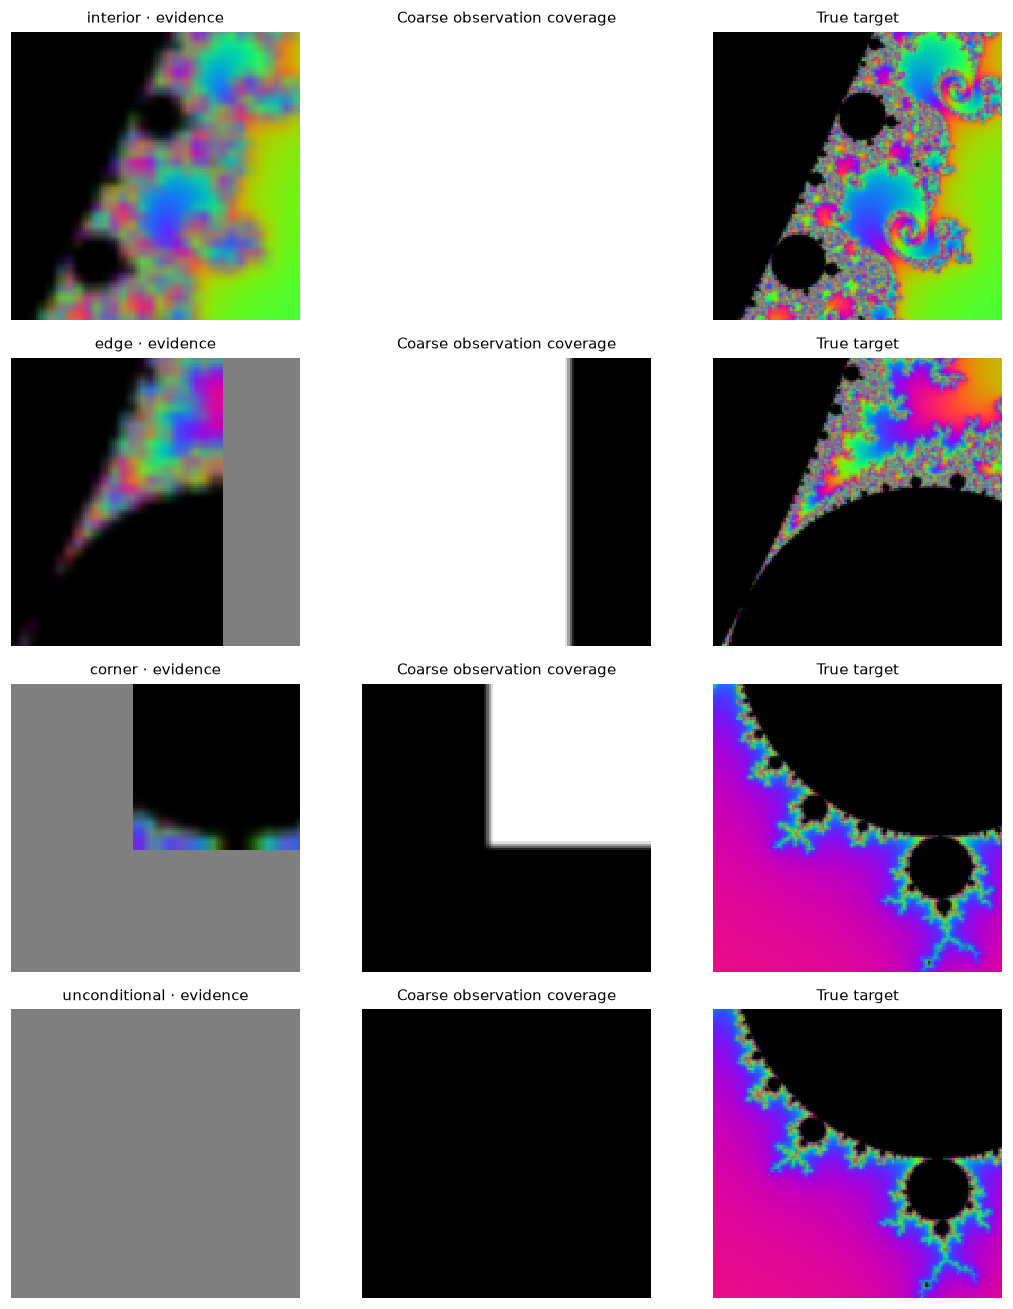

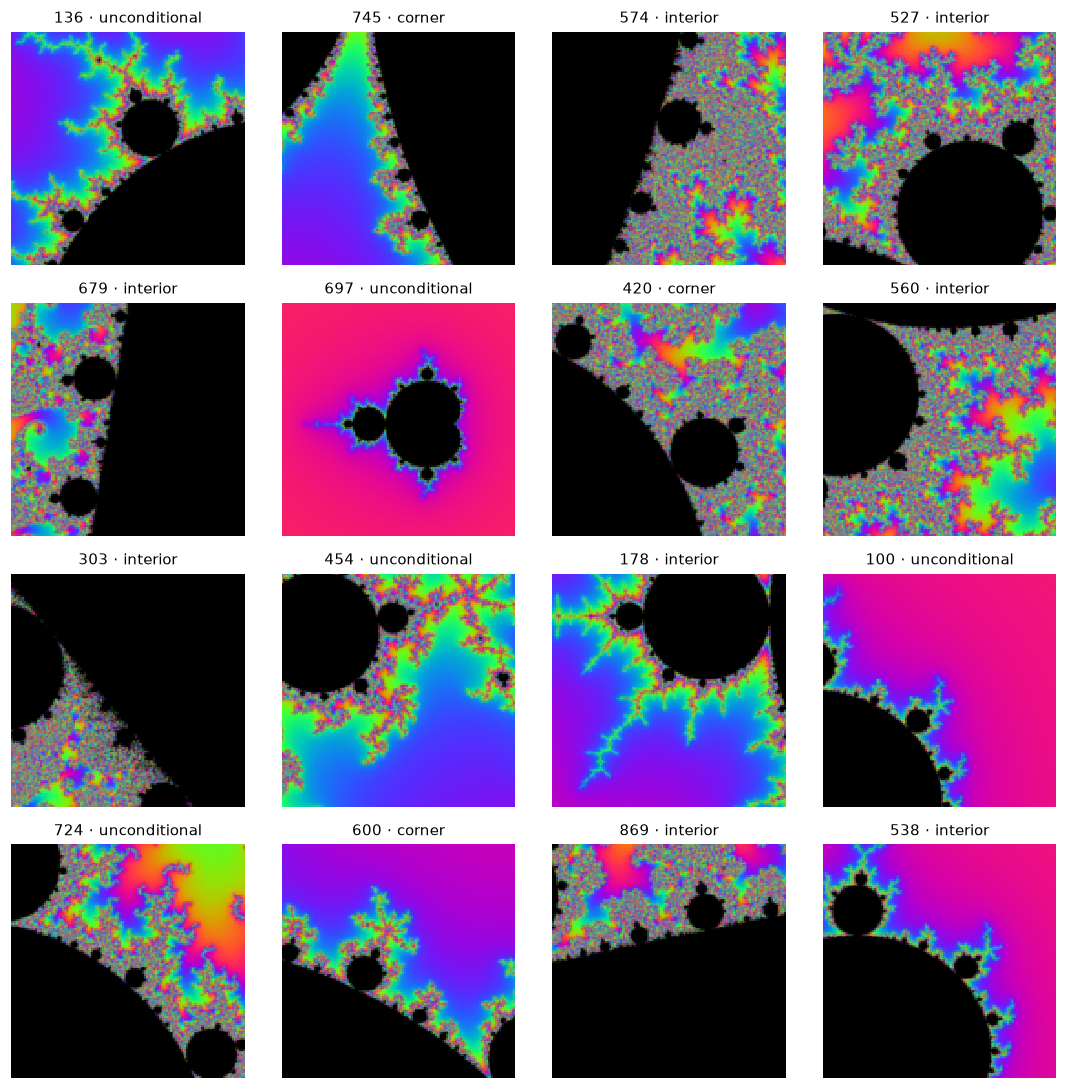

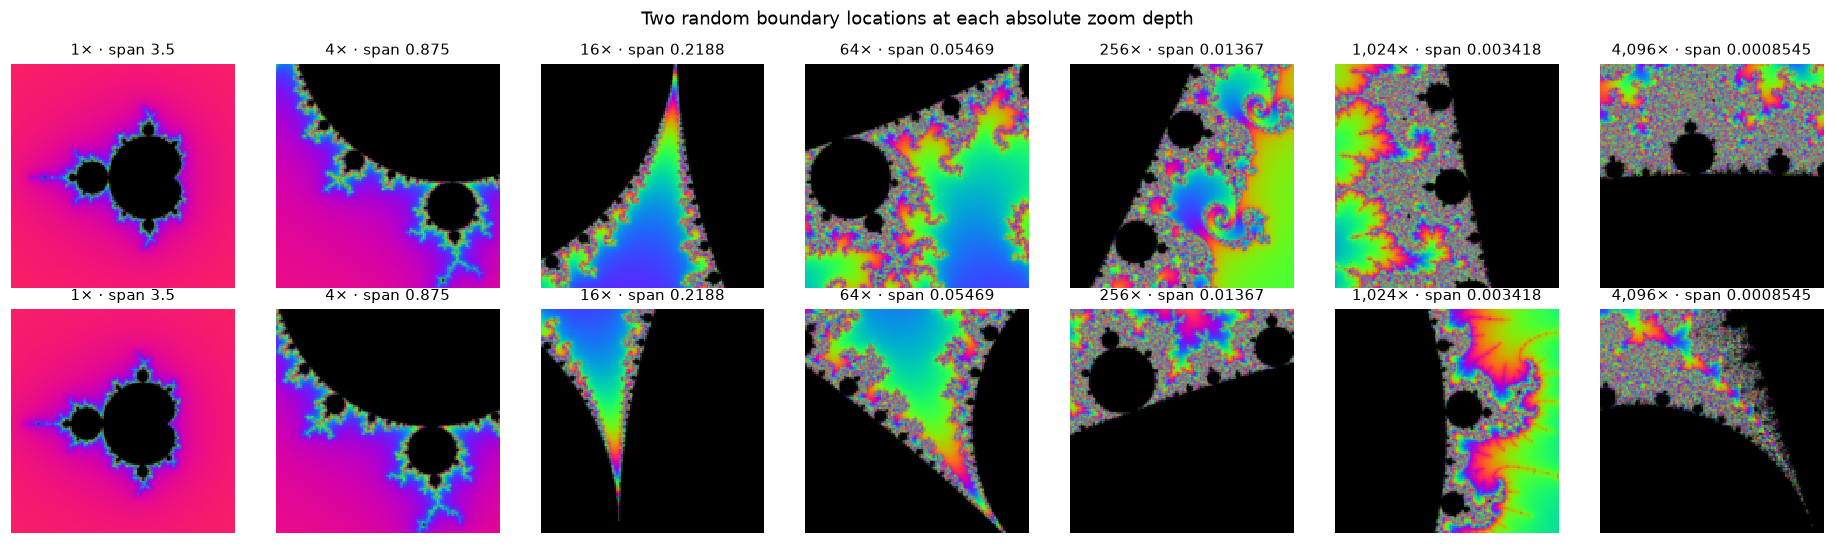

In [4]:
new_directory = DATA / "zoom4x-multiscale-128"
balanced_directory = DATA / "bw64-balanced-1000"
if new_directory.exists():
    fresh = load(new_directory / "train.pt")
    modes = ("interior", "edge", "corner", "unconditional")
    ids = [next(i for i,r in enumerate(fresh["records"]) if r["mode"]==mode) for mode in modes]
    fig, axes = plt.subplots(4,3,figsize=(10,12))
    for row,(i,mode) in enumerate(zip(ids,modes)):
        show_image(axes[row,0],fresh["inputs"][i],f"{mode} · evidence")
        show_image(axes[row,1],fresh["masks"][i],"Coarse observation coverage")
        show_image(axes[row,2],fresh["targets"][i],"True target")
    fig.tight_layout(); display(fig); plt.close(fig)
    ids = random.Random(20261016).sample(range(len(fresh["targets"])),16)
    fig,axes=plt.subplots(4,4,figsize=(10,10))
    for ax,i in zip(axes.flat,ids):show_image(ax,fresh["targets"][i],f"{i} · {fresh['records'][i]['mode']}")
    fig.tight_layout(); display(fig); plt.close(fig)
    fig,axes=plt.subplots(2,7,figsize=(17,5))
    for depth in range(7):
        ids=[i for i,r in enumerate(fresh["records"]) if r["zoom_depth"]==depth]
        for row,i in enumerate(ids[:2]):
            show_image(axes[row,depth],fresh["targets"][i],f"{4**depth:,}× · span {fresh['records'][i]['span']:.4g}")
    fig.suptitle("Two random boundary locations at each absolute zoom depth")
    fig.tight_layout(); display(fig); plt.close(fig)


## Scale distribution and split limitations

Both splits have explicit quotas across seven depths. Recursive boundary sampling finds smaller structures instead of repeatedly cropping a low-resolution overview anchor. Initial boundary anchor groups differ across splits, but broad views and image footprints can overlap. This is not a held-out-geography benchmark.

Split,Examples,Depth counts,Span range
train,900,"{0: 129, 1: 129, 2: 129, 3: 129, 4: 128, 5: 128, 6: 128}",0.0008545–3.5
val,100,"{0: 15, 1: 15, 2: 14, 3: 14, 4: 14, 5: 14, 6: 14}",0.0008545–3.5


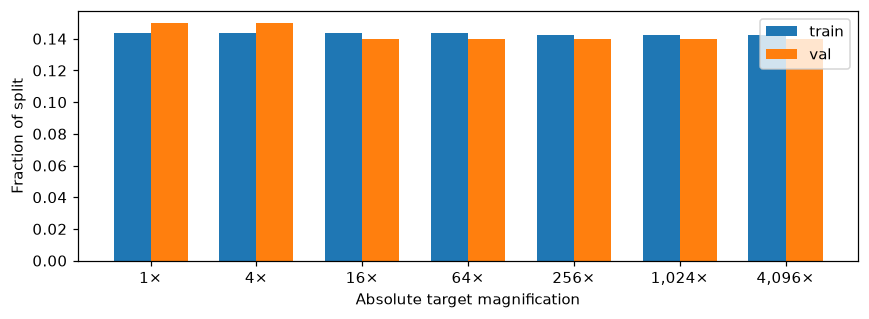

Initial boundary anchor groups differ. Broad target/parent footprints can still overlap.


In [5]:
if new_directory.exists():
    from collections import Counter
    a,b=[load(new_directory/f"{s}.pt") for s in ("train","val")]
    for payload in (a,b):
        for k in ("inputs","targets","masks"):
            assert torch.isfinite(payload[k]).all() and payload[k].min()>=0 and payload[k].max()<=1
        counts=Counter(r["zoom_depth"] for r in payload["records"])
        assert set(counts)==set(range(7)) and max(counts.values())-min(counts.values())<=1
    table(("Split","Examples","Depth counts","Span range"),[
        (s,len(payload["targets"]),dict(sorted(Counter(r["zoom_depth"] for r in payload["records"]).items())),
         f"{min(r['span'] for r in payload['records']):.4g}–{max(r['span'] for r in payload['records']):.4g}")
        for s,payload in (("train",a),("val",b))])
    fig,ax=plt.subplots(figsize=(8,3))
    for j,(name,payload) in enumerate((("train",a),("val",b))):
        counts=Counter(r["zoom_depth"] for r in payload["records"])
        ax.bar(np.arange(7)+(j-.5)*.35,[counts[d]/len(payload["records"]) for d in range(7)],width=.35,label=name)
    ax.set(xticks=range(7),xticklabels=[f"{4**d:,}×" for d in range(7)],xlabel="Absolute target magnification",ylabel="Fraction of split")
    ax.legend();fig.tight_layout();display(fig);plt.close(fig)
    print("Initial boundary anchor groups differ. Broad target/parent footprints can still overlap.")


## Check the existing train/validation split

The older balanced dataset separates anchor groups, but its image footprints can overlap.
This audit checks actual view rectangles, not only group labels. Overlap is evidence that the split
is not a clean test of unseen geographic regions; it does not by itself prove identical images.
“Comparable scale” means spans differ by at most a factor of two.

Audit,Result
Validation images,100
Validation images overlapping any training footprint,100
"Over 50% overlap of smaller footprint, comparable scale",96
Exact 8-bit image duplicates across splits,0


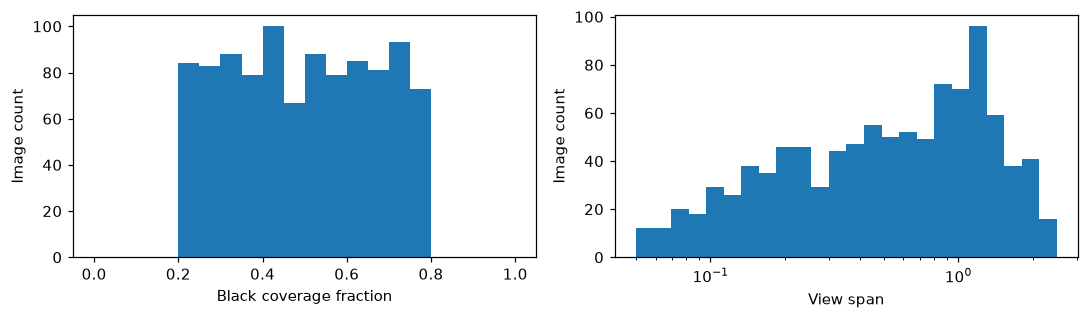

In [6]:
if balanced_directory.exists():
    train = load(balanced_directory / "train.pt")
    val = load(balanced_directory / "val.pt")
    train_boxes = torch.tensor([[*r["center"], r["span"]] for r in train["records"]])
    val_boxes = torch.tensor([[*r["center"], r["span"]] for r in val["records"]])
    low = torch.maximum(train_boxes[None,:,:2]-train_boxes[None,:,2:]/2,
                        val_boxes[:,None,:2]-val_boxes[:,None,2:]/2)
    high = torch.minimum(train_boxes[None,:,:2]+train_boxes[None,:,2:]/2,
                         val_boxes[:,None,:2]+val_boxes[:,None,2:]/2)
    intersection = (high-low).clamp_min(0).prod(-1)
    fraction = intersection/torch.minimum(train_boxes[None,:,2]**2, val_boxes[:,None,2]**2)
    ratio = train_boxes[None,:,2]/val_boxes[:,None,2]
    similar = (fraction>.5) & (ratio>=.5) & (ratio<=2)
    def hashes(images):
        return {hashlib.sha256((im*255).round().byte().numpy().tobytes()).hexdigest() for im in images}
    table(("Audit", "Result"), [
        ("Validation images", len(val_boxes)),
        ("Validation images overlapping any training footprint", int((intersection>0).any(1).sum())),
        ("Over 50% overlap of smaller footprint, comparable scale", int(similar.any(1).sum())),
        ("Exact 8-bit image duplicates across splits", len(hashes(train["images"]) & hashes(val["images"]))),
    ])
    records = train["records"]+val["records"]
    black_fraction = 1-torch.cat((train["images"], val["images"])).mean((1,2,3))
    fig, axes = plt.subplots(1,2,figsize=(10,3))
    axes[0].hist(black_fraction.numpy(), bins=np.linspace(0,1,21))
    axes[0].set(xlabel="Black coverage fraction", ylabel="Image count")
    axes[1].hist([r["span"] for r in records], bins=np.geomspace(.05,2.5,25))
    axes[1].set(xscale="log", xlabel="View span", ylabel="Image count")
    fig.tight_layout(); display(fig); plt.close(fig)

## Before training

- Seven balanced absolute zoom depths; every conditional pair still refines a 4× zoom.
- Full, partial, and absent RGB evidence share the same tensor format and masks.
- Overview views and crop footprints can overlap across splits; this is not held-out geography.
- Four samples per pixel and 8,192 iterations are finite rendering budgets, not convergence guarantees.
- The legacy paired trainer does not consume masks and refuses mixed examples. Shared mask-aware training remains to implement.
- Earlier datasets are preserved and available in the dataset selector.
